# 3.1 Spatial autocorrelation of nursery fees (H-b, fee side)

Do full-day nursery fees cluster in space, or is each centre's price independent of its neighbours'?
This notebook aggregates the listed `FULL_DAY_SC_NURSERY_FEE` of every centre to the median fee of
its planning area and of its subzone, then tests each surface with global Moran's I (999 permutations)
and maps the local Moran (LISA) clusters. Its planning-area table is the fee input of the income
regressions in 3.2 (OLS) and 3.3 (GWR). The code is Daryl's `scripts/spatial_autocorrelation_nursery_fee.py`;
the statistics are pure numpy (symmetric 4-nearest-neighbour weights on area-weighted centroids,
row-standardised) and the helpers now live in `src/bt4015/moran.py`.

**Change from the script (2026-11-10).** Daryl ran this on the 2021 GeoJSON
(`data/ChildCareServices_2021.geojson`, 1,363 fees in 38 planning areas). The team decision of
2026-11-01 (`docs/decisions.md`) is that every analysis uses the canonical 2026 layer, so the centre
input is now built from `output/childcare_centres_2026.gpkg` (1,796 centres, 1,587 listed fees; the one
S$0 fee is treated as missing). Everything after the load is unchanged. The 2021 results are kept in the
stage README for comparison.

**Inputs**
- `output/childcare_centres_2026.gpkg`, layer `centres` (Jessie, stage 1): 1,796 centres, EPSG:3414, fee column `FULL_DAY_SC_NURSERY_FEE`.
- `data/MasterPlanSubZones_2019.geojson` (URA Master Plan 2019 subzones, with `PLN_AREA_N` and `SUBZONE_N`).

**Outputs**
- `output/spatial_autocorrelation_nursery_fee_planning_area/planning_area_nursery_fee_moran.csv` (read by 3.2 and 3.3), `global_moran_permutations.csv`, `analysis_summary.md` and six PNGs.
- `output/spatial_autocorrelation_nursery_fee_subzone/subzone_nursery_fee_moran.csv`, `global_moran_permutations.csv`, `analysis_summary.md` and seven PNGs.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "bt4015").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from bt4015.paths import DATA, OUT, FIG, LARGE

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyogrio

from bt4015.moran import (
    assign_centres, benjamini_hochberg, dataframe_to_markdown, draw_fee_map,
    draw_global_moran_cluster_map, draw_lisa_map, draw_moran_scatter, draw_permutation,
    knn_weights, lisa_quadrants, load_geojson, permutation_inference, planning_area_centroids,
    prepare_subzones,
)

CENTRES_GPKG = OUT / "childcare_centres_2026.gpkg"      # canonical centre layer (decision 2026-11-01)
SUBZONES_GEOJSON = DATA / "MasterPlanSubZones_2019.geojson"
K = 4                 # nearest neighbours in the symmetric KNN graph
PERMUTATIONS = 999    # random permutations for global and local inference
SEED = 4015           # project seed
OUT_PA = OUT / "spatial_autocorrelation_nursery_fee_planning_area"   # same folders as Daryl's script
OUT_SZ = OUT / "spatial_autocorrelation_nursery_fee_subzone"
for folder in (OUT_PA, OUT_SZ):
    folder.mkdir(parents=True, exist_ok=True)

## 1. Load the 2026 centres as lon/lat points

Daryl's loader walks a GeoJSON feature collection in EPSG:4326, so the GeoPackage layer is reprojected
and wrapped in the same structure (`properties.FULL_DAY_SC_NURSERY_FEE`, `properties.NAME`,
`geometry.coordinates = [lon, lat]`). Only the 1,587 centres with `fee_status == "listed"` carry a fee;
PALS Preschool (RC1909) is listed at S$0, which is a data error, so it is set to null. That leaves
1,586 fees.

In [2]:
# 1. Read the canonical layer and reproject to WGS 84 for the lon/lat point-in-polygon loader.
centres = pyogrio.read_dataframe(CENTRES_GPKG, layer="centres").to_crs(4326)
print(f"centres in layer: {len(centres):,}; fee_status counts:")
print(centres["fee_status"].value_counts().to_string())

# 2. One listed fee is S$0 (impossible for a full-day programme) -> treat as missing. changed 2026-11-10.
zero_fee = centres["FULL_DAY_SC_NURSERY_FEE"].eq(0)
print("\nS$0 fee set to null:", centres.loc[zero_fee, ["centre_code", "centre_name"]].to_dict("records"))
fee = centres["FULL_DAY_SC_NURSERY_FEE"].where(~zero_fee)
print(f"usable fees: {fee.notna().sum():,} of {len(centres):,}")

# 3. Wrap as a GeoJSON-like feature collection so assign_centres() runs unchanged.
centres_json = {
    "type": "FeatureCollection",
    "features": [
        {
            "type": "Feature",
            "properties": {"NAME": name, "FULL_DAY_SC_NURSERY_FEE": None if pd.isna(f) else float(f)},
            "geometry": {"type": "Point", "coordinates": [float(pt.x), float(pt.y)]},
        }
        for name, f, pt in zip(centres["centre_name"], fee, centres.geometry)
    ],
}
subzones_json = load_geojson(SUBZONES_GEOJSON)
print(f"subzone features: {len(subzones_json['features'])}")

centres in layer: 1,796; fee_status counts:
fee_status
listed                            1587
no_nursery_full_day_sc_listing     193
conflicting_fees                    15
no_centre_code                       1

S$0 fee set to null: [{'centre_code': 'RC1909', 'centre_name': 'PALS Preschool'}]
usable fees: 1,586 of 1,796
subzone features: 332


## 2. One function for both spatial units

The same pipeline runs at planning-area level (`PLN_AREA_N`, pieces merged by name) and subzone level
(`SUBZONE_N`): assign each fee point to its polygon, take the median fee per unit, build the symmetric
4-nearest-neighbour graph on area-weighted centroids, standardise the medians, and run the permutation
inference for the global and local statistics. Local p-values are exploratory; Benjamini-Hochberg
q-values are added for a confirmatory reading.

In [3]:
def fee_moran(name_field, unit_label):
    """Aggregate fees to the polygons named by `name_field` and run global + local Moran's I.

    Returns a dict with the subzone records, the per-unit table (area_df), the standardised values,
    the lag, the global statistics and the permutation draws.
    """
    # 1. Polygons keyed by the aggregation name; a planning area is several subzone pieces.
    subzones = prepare_subzones(subzones_json, name_field=name_field)
    # 2. Point-in-polygon: every centre with a valid fee gets its unit name.
    centre_df, diagnostics = assign_centres(centres_json, subzones)
    # 3. Median fee per unit (mean, count and SD kept for context).
    area_df = (
        centre_df.groupby("planning_area")["fee"]
        .agg(mean_fee_sgd="mean", median_fee_sgd="median", centre_count="size", fee_sd_sgd="std")
        .reset_index()
        .sort_values("planning_area")
        .reset_index(drop=True)
    )
    # 4. Area-weighted centroid per unit -> symmetric KNN graph, row-standardised.
    centroid_lookup = planning_area_centroids(subzones)
    centroid_array = np.asarray([centroid_lookup[name] for name in area_df["planning_area"]])
    area_df["centroid_lon"] = centroid_array[:, 0]
    area_df["centroid_lat"] = centroid_array[:, 1]
    binary, weights = knn_weights(centroid_array, K)
    # 5. Standardise the medians (population SD, as in the script) and compute the spatial lag.
    fees = area_df["median_fee_sgd"].to_numpy()
    z = (fees - fees.mean()) / fees.std(ddof=0)
    lag = weights @ z
    # 6. Permutation inference: global pseudo-p and conditional-randomisation local p.
    observed_i, global_p, global_perm, local_i, local_p = permutation_inference(z, weights, PERMUTATIONS, SEED)
    expected_i = -1.0 / (len(z) - 1)
    local_q = benjamini_hochberg(local_p)
    # 7. Quadrant labels, with and without a significance filter.
    raw_clusters = lisa_quadrants(z, lag)
    area_df["standardised_fee"] = z
    area_df["spatial_lag"] = lag
    area_df["local_moran_i"] = local_i
    area_df["local_permutation_p"] = local_p
    area_df["local_fdr_q"] = local_q
    area_df["lisa_quadrant"] = raw_clusters
    area_df["lisa_cluster_p05"] = np.where(local_p < 0.05, raw_clusters, "Not significant")
    area_df["lisa_cluster_fdr05"] = np.where(local_q < 0.05, raw_clusters, "Not significant")
    area_df["neighbour_count"] = binary.sum(axis=1).astype(int)
    print(f"{unit_label}: {diagnostics['total_centres']:,} centre features, "
          f"{diagnostics['null_or_invalid_fee']:,} without a usable fee, "
          f"{diagnostics['outside_subzones']:,} outside every polygon -> {len(centre_df):,} centres in "
          f"{len(area_df)} {unit_label.lower()}s")
    print(f"  global Moran's I = {observed_i:.4f} (expected {expected_i:.4f}), pseudo-p = {global_p:.4f}")
    print("  local clusters at p < 0.05:", area_df["lisa_cluster_p05"].value_counts().to_dict())
    print("  local clusters at FDR q < 0.05:", area_df["lisa_cluster_fdr05"].value_counts().to_dict())
    return dict(subzones=subzones, centre_df=centre_df, diagnostics=diagnostics, area_df=area_df,
                z=z, lag=lag, observed_i=observed_i, expected_i=expected_i, global_p=global_p,
                global_perm=global_perm, unit_label=unit_label, name_field=name_field)


def show_plot(draw_function, path, figsize=(9, 7)):
    """Draw one figure on a fresh axis, save it under `path` and show it inline."""
    fig, ax = plt.subplots(figsize=figsize)
    draw_function(ax)
    fig.tight_layout()
    fig.savefig(path, dpi=220, bbox_inches="tight")
    plt.show()


def write_summary(result, out_dir, unit_slug, unit_label_plural):
    """Write Daryl's analysis_summary.md (method, coverage, global I, significant local clusters)."""
    area_df, diagnostics = result["area_df"], result["diagnostics"]
    significant = area_df.loc[area_df["local_permutation_p"] < 0.05, [
        "planning_area", "median_fee_sgd", "centre_count", "lisa_cluster_p05", "local_moran_i",
        "local_permutation_p", "local_fdr_q"]].rename(columns={"planning_area": unit_slug}).sort_values(
        ["lisa_cluster_p05", "local_permutation_p"])
    unit_label = result["unit_label"]
    direction = "positive" if result["observed_i"] > result["expected_i"] else "negative"
    decision = "statistically significant" if result["global_p"] < 0.05 else "not statistically significant"
    summary = f"""# Spatial autocorrelation of full-day SC nursery fees by {unit_label.lower()}

## Method

- Source points: `output/childcare_centres_2026.gpkg` layer `centres` (canonical 2026 layer); null `FULL_DAY_SC_NURSERY_FEE` records and the one S$0 fee excluded.
- Spatial unit: 2019 {unit_label_plural} (`{result['name_field']}`) from `data/MasterPlanSubZones_2019.geojson`.
- Area statistic: median centre fee in SGD. The centre count and mean are retained for context.
- Spatial weights: symmetric {K}-nearest-neighbour graph based on area-weighted {unit_label.lower()} centroids, row-standardised.
- Inference: {PERMUTATIONS:,} random permutations, seed {SEED}. Local p-values are exploratory; Benjamini-Hochberg FDR q-values are also reported.

## Data coverage

- Centre features: {diagnostics['total_centres']:,}
- Excluded null/invalid fees: {diagnostics['null_or_invalid_fee']:,}
- Valid fee points outside a {unit_label.lower()} polygon: {diagnostics['outside_subzones']:,}
- Centres analysed: {len(result['centre_df']):,}
- {unit_label_plural.capitalize()} with at least one valid centre: {len(area_df)}

## Global Moran's I

- Observed I: **{result['observed_i']:.4f}**
- Randomisation expectation: **{result['expected_i']:.4f}**
- Permutation pseudo-p: **{result['global_p']:.4f}**

The area-level median fees show **{direction} spatial autocorrelation**, and the result is **{decision} at the 5% level** under this weights specification.

## Local Moran clusters (raw permutation p < 0.05)

{dataframe_to_markdown(significant) if len(significant) else f'No {unit_label.lower()} is locally significant at raw p < 0.05.'}

Note: local results involve multiple comparisons. Prefer `local_fdr_q` / `lisa_cluster_fdr05` when confirmatory control of false discoveries is required. Results describe {unit_label.lower()} medians, not individual-centre fee similarity.
"""
    (out_dir / "analysis_summary.md").write_text(summary, encoding="utf-8")
    return significant

## 3. Planning-area level

42 planning areas have at least one listed fee. Fees cluster strongly: the central high-fee areas
(Newton, Orchard, River Valley, Tanglin, the Downtown Core) sit next to each other, and the
S$610-650 anchor-operator belt covers the HDB towns.

In [4]:
pa = fee_moran("PLN_AREA_N", "Planning Area")
pa_df = pa["area_df"]
pa_df.rename(columns={"planning_area": "planning_area"}).to_csv(OUT_PA / "planning_area_nursery_fee_moran.csv", index=False)
pd.DataFrame({"permutation": np.arange(1, PERMUTATIONS + 1), "moran_i": pa["global_perm"]}).to_csv(
    OUT_PA / "global_moran_permutations.csv", index=False)
print(pa_df[["planning_area", "median_fee_sgd", "centre_count", "lisa_cluster_p05", "local_permutation_p", "local_fdr_q"]]
      .sort_values("median_fee_sgd", ascending=False).head(12).round(3).to_string(index=False))

Planning Area: 1,796 centre features, 210 without a usable fee, 0 outside every polygon -> 1,586 centres in 42 planning areas
  global Moran's I = 0.5110 (expected -0.0244), pseudo-p = 0.0010
  local clusters at p < 0.05: {'Not significant': 23, 'Low-Low': 8, 'High-High': 8, 'Low-High': 2, 'High-Low': 1}
  local clusters at FDR q < 0.05: {'Not significant': 30, 'High-High': 8, 'Low-High': 2, 'Low-Low': 2}
   planning_area  median_fee_sgd  centre_count lisa_cluster_p05  local_permutation_p  local_fdr_q
    MARINA SOUTH          3010.0             1        High-High                0.002        0.014
SOUTHERN ISLANDS          2730.0             1  Not significant                0.074        0.135
         ORCHARD          2480.0             3        High-High                0.004        0.024
   DOWNTOWN CORE          2350.0            18        High-High                0.008        0.031
         TANGLIN          2291.0            11        High-High                0.007        0.031
   

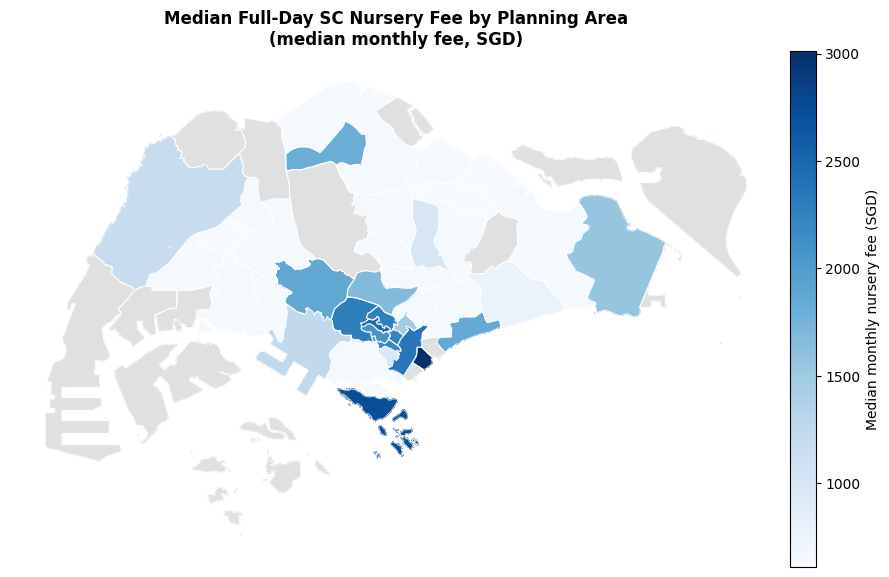

In [5]:
show_plot(lambda ax: draw_fee_map(ax, pa["subzones"], pa_df, "Planning Area"),
          OUT_PA / "nursery_fee_choropleth.png", figsize=(9, 6.3))

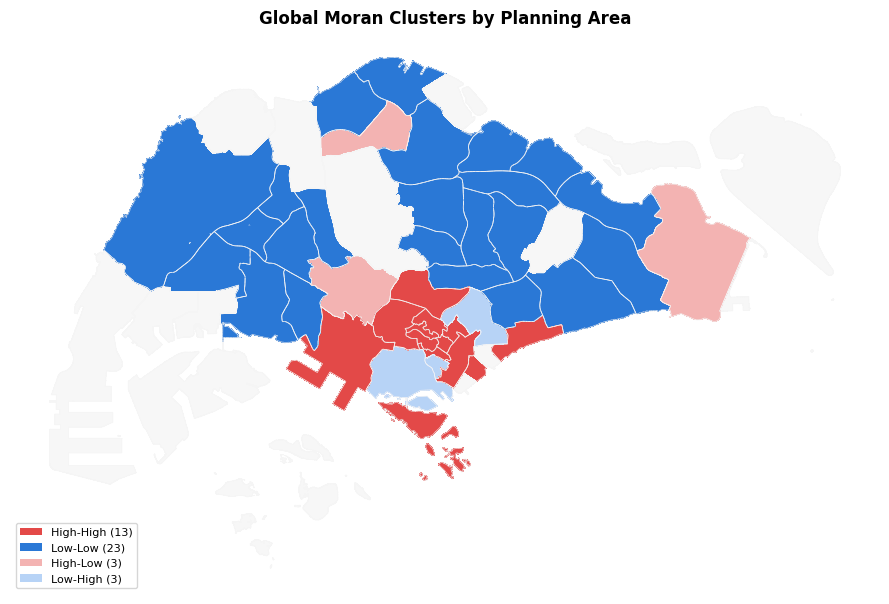

In [6]:
show_plot(lambda ax: draw_global_moran_cluster_map(ax, pa["subzones"], pa_df, "Planning Area"),
          OUT_PA / "global_moran_cluster_map.png")

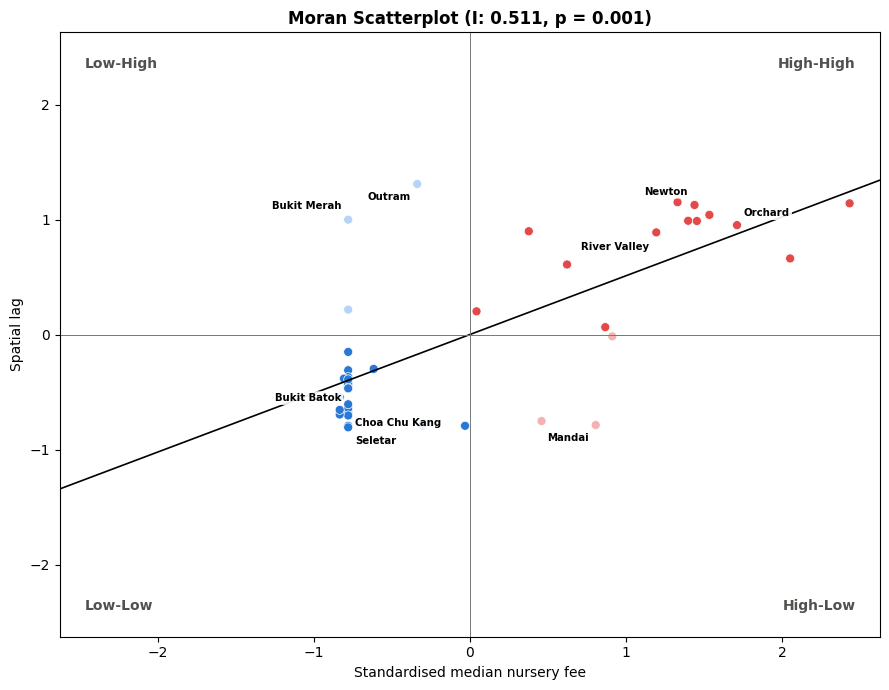

In [7]:
show_plot(lambda ax: draw_moran_scatter(ax, pa["z"], pa["lag"], pa["observed_i"], pa["global_p"],
                                        pa_df["planning_area"].to_numpy(), annotate_names=True),
          OUT_PA / "global_moran_scatterplot.png")

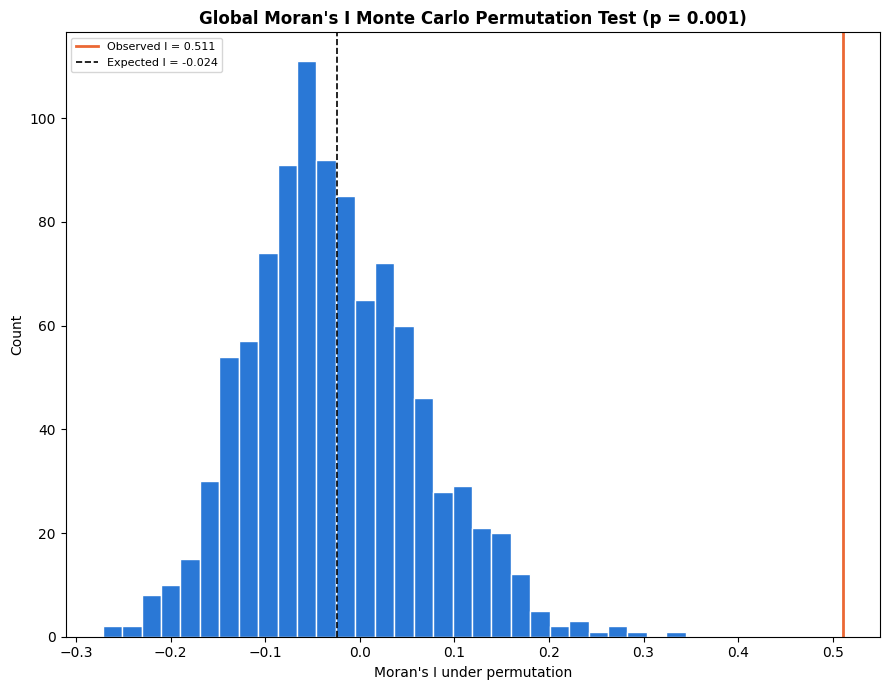

In [8]:
show_plot(lambda ax: draw_permutation(ax, pa["global_perm"], pa["observed_i"], pa["expected_i"], pa["global_p"]),
          OUT_PA / "global_moran_permutation.png")

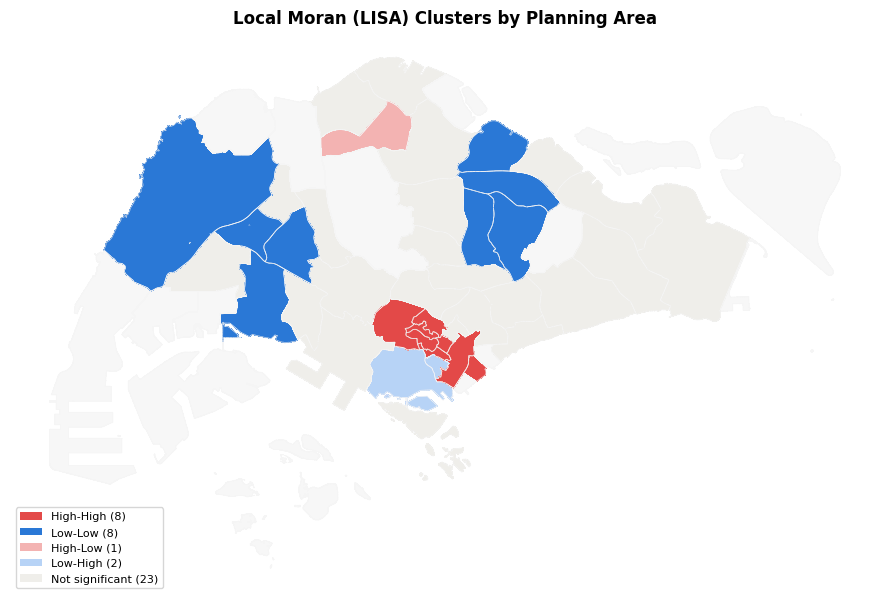

In [9]:
show_plot(lambda ax: draw_lisa_map(ax, pa["subzones"], pa_df, "Planning Area"),
          OUT_PA / "local_moran_lisa_map.png")

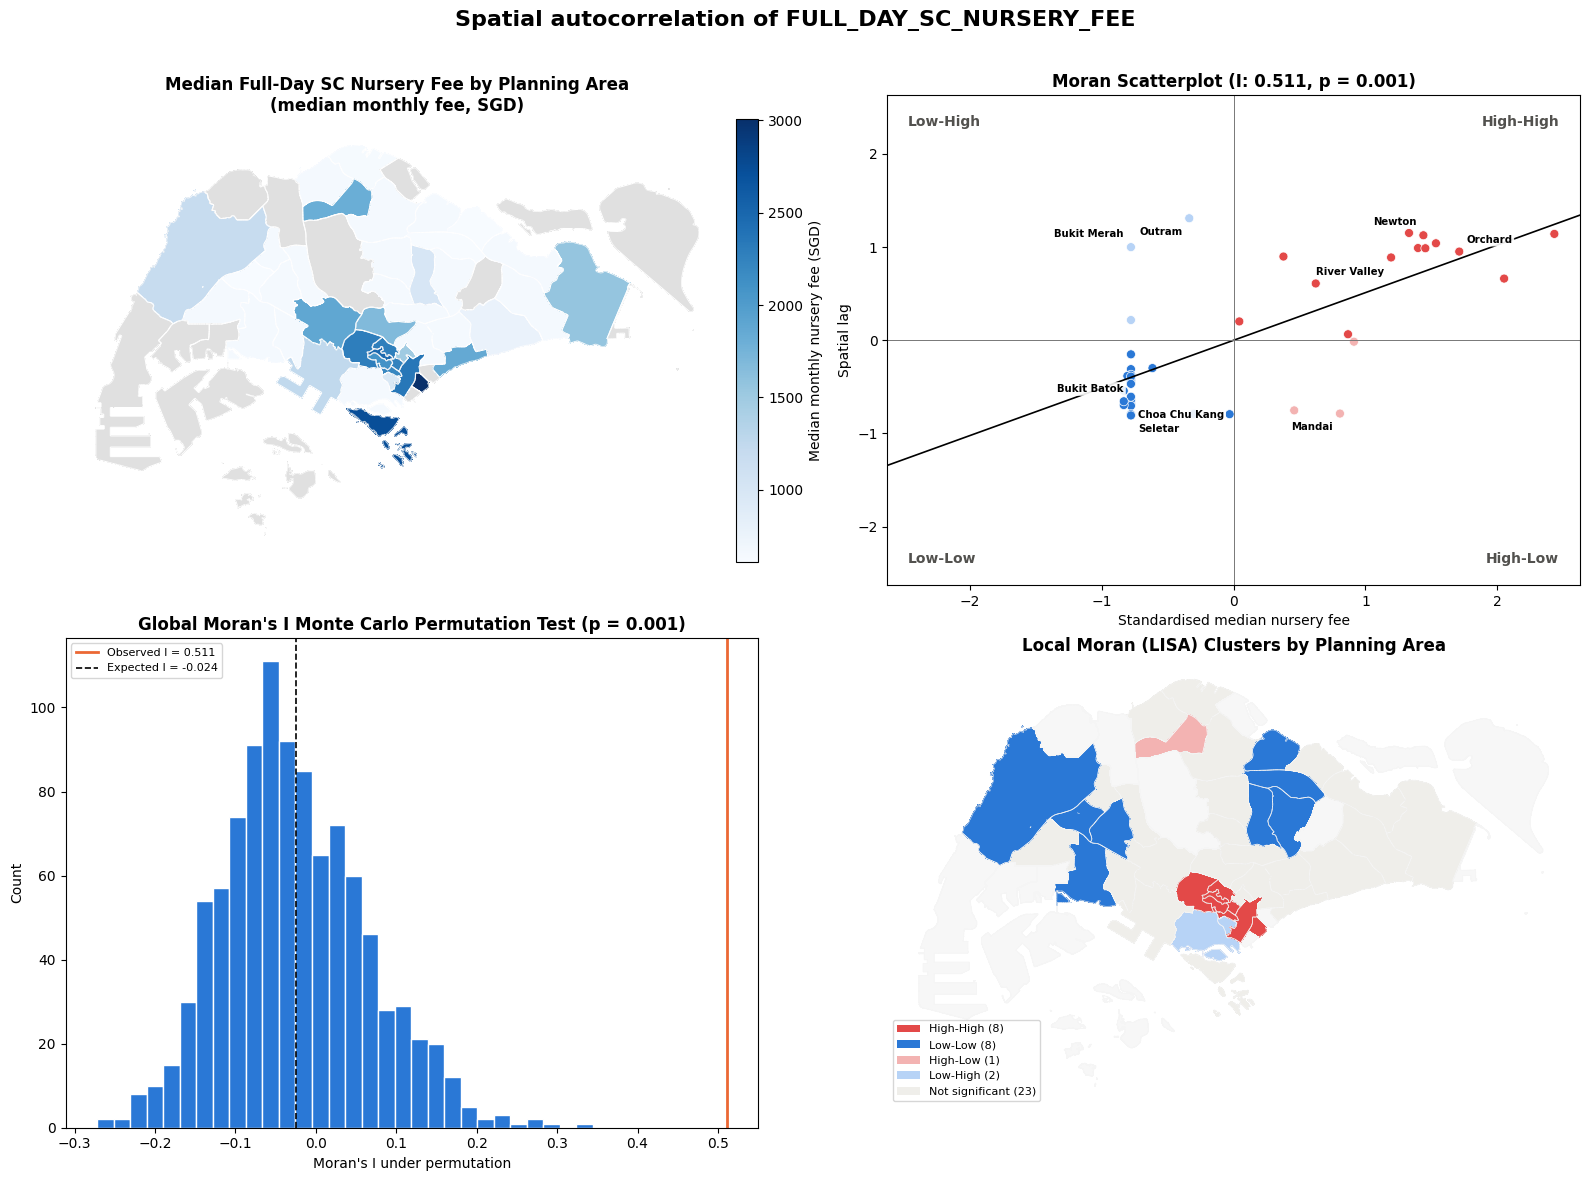

In [10]:
# Four-panel overview: choropleth, Moran scatter, permutation histogram, LISA map.
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
draw_fee_map(axes[0, 0], pa["subzones"], pa_df, "Planning Area")
draw_moran_scatter(axes[0, 1], pa["z"], pa["lag"], pa["observed_i"], pa["global_p"],
                   pa_df["planning_area"].to_numpy(), annotate_names=True)
draw_permutation(axes[1, 0], pa["global_perm"], pa["observed_i"], pa["expected_i"], pa["global_p"])
draw_lisa_map(axes[1, 1], pa["subzones"], pa_df, "Planning Area")
fig.suptitle("Spatial autocorrelation of FULL_DAY_SC_NURSERY_FEE", fontsize=16, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.97))
fig.savefig(OUT_PA / "spatial_autocorrelation_overview.png", dpi=220, bbox_inches="tight")
plt.show()

In [11]:
significant_pa = write_summary(pa, OUT_PA, "planning_area", "planning areas")
print(f"planning areas locally significant at p < 0.05: {len(significant_pa)}")
print(significant_pa.round(4).to_string(index=False))

planning areas locally significant at p < 0.05: 19
          planning_area  median_fee_sgd  centre_count lisa_cluster_p05  local_moran_i  local_permutation_p  local_fdr_q
                 MUSEUM          2250.0             1        High-High         1.3833                0.001       0.0140
        SINGAPORE RIVER          2200.0             6        High-High         1.5309                0.001       0.0140
           MARINA SOUTH          3010.0             1        High-High         2.7757                0.002       0.0140
                 NEWTON          2280.0             4        High-High         1.6211                0.002       0.0140
                ORCHARD          2480.0             3        High-High         1.6281                0.004       0.0240
           RIVER VALLEY          2100.0             7        High-High         1.0605                0.006       0.0305
                TANGLIN          2291.0            11        High-High         1.4353                0.007   

## 4. Subzone level

The same test on the 2019 subzones. More units, so the KNN graph is finer and the LISA map picks out
the central high-fee cluster and the low-low belts in the HDB towns. Local p-values are exploratory
(hundreds of tests); the FDR column is the conservative reading.

In [12]:
sz = fee_moran("SUBZONE_N", "Subzone")
sz_df = sz["area_df"]
sz_df.rename(columns={"planning_area": "subzone"}).to_csv(OUT_SZ / "subzone_nursery_fee_moran.csv", index=False)
pd.DataFrame({"permutation": np.arange(1, PERMUTATIONS + 1), "moran_i": sz["global_perm"]}).to_csv(
    OUT_SZ / "global_moran_permutations.csv", index=False)

Subzone: 1,796 centre features, 210 without a usable fee, 0 outside every polygon -> 1,586 centres in 232 subzones
  global Moran's I = 0.4455 (expected -0.0043), pseudo-p = 0.0010
  local clusters at p < 0.05: {'Not significant': 164, 'Low-Low': 35, 'High-High': 27, 'Low-High': 4, 'High-Low': 2}
  local clusters at FDR q < 0.05: {'Not significant': 215, 'High-High': 16, 'Low-High': 1}


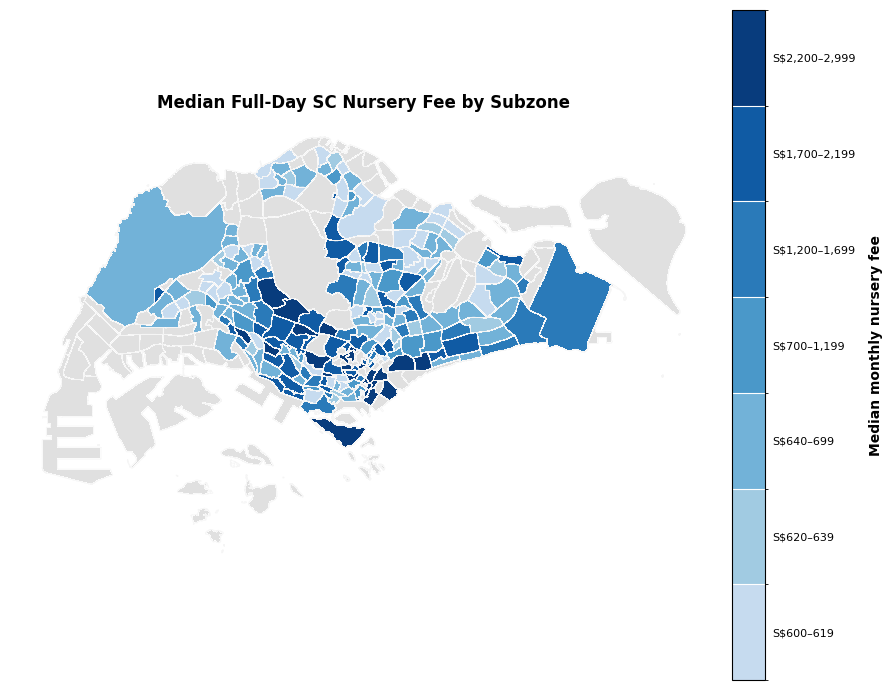

In [13]:
show_plot(lambda ax: draw_fee_map(ax, sz["subzones"], sz_df, "Subzone"), OUT_SZ / "nursery_fee_choropleth.png")

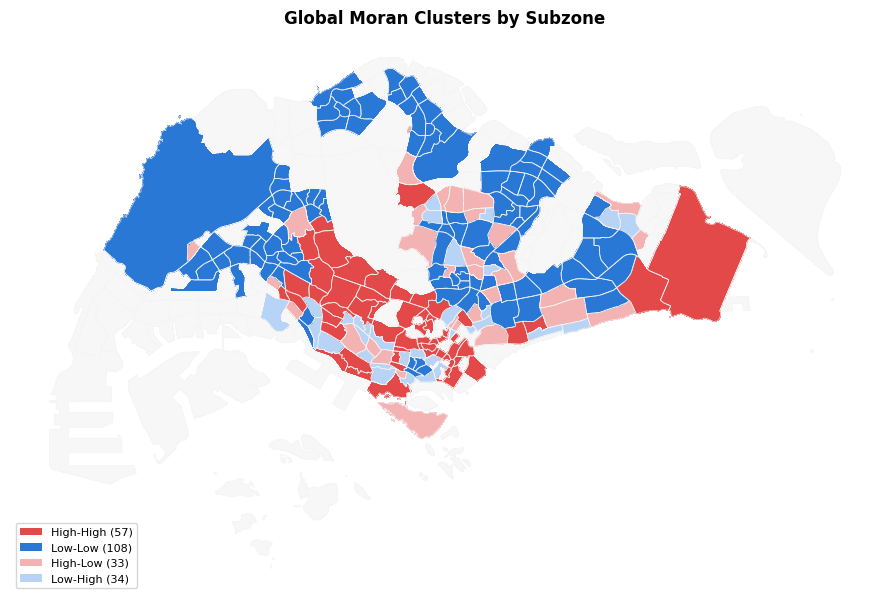

In [14]:
show_plot(lambda ax: draw_global_moran_cluster_map(ax, sz["subzones"], sz_df, "Subzone"),
          OUT_SZ / "global_moran_cluster_map.png")

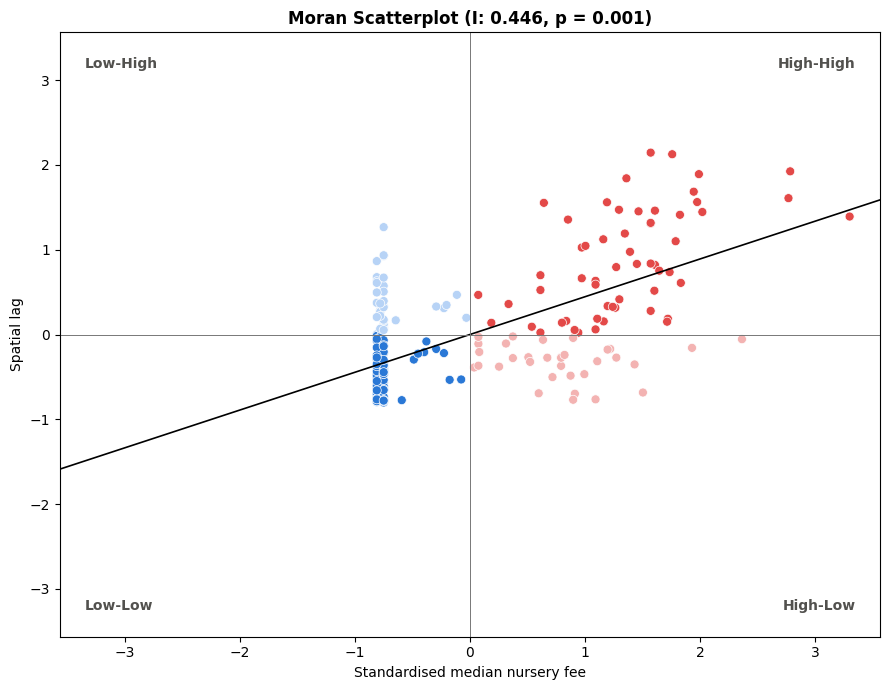

In [15]:
show_plot(lambda ax: draw_moran_scatter(ax, sz["z"], sz["lag"], sz["observed_i"], sz["global_p"],
                                        sz_df["planning_area"].to_numpy(), annotate_names=False),
          OUT_SZ / "global_moran_scatterplot.png")

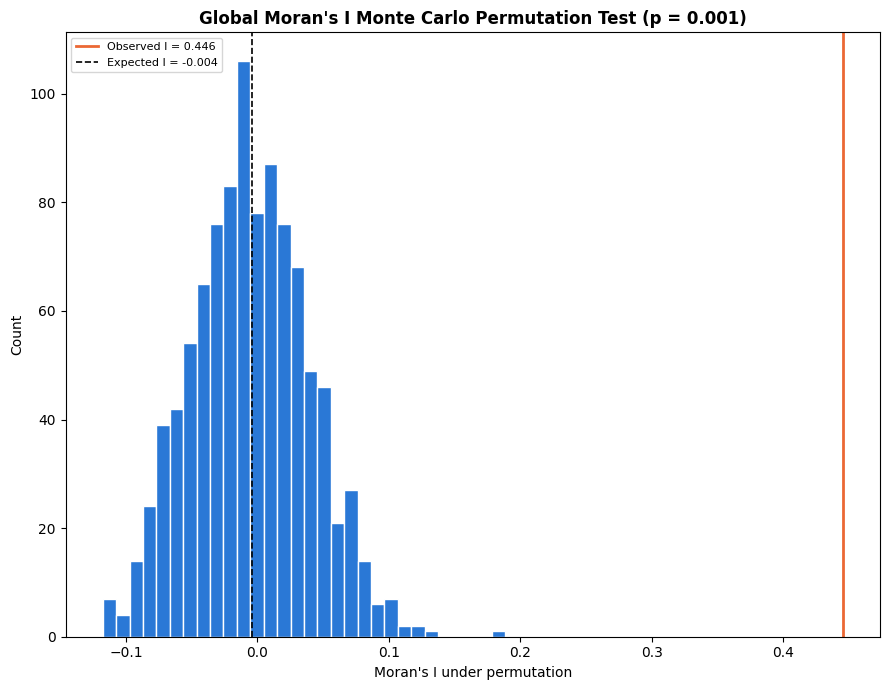

In [16]:
show_plot(lambda ax: draw_permutation(ax, sz["global_perm"], sz["observed_i"], sz["expected_i"], sz["global_p"]),
          OUT_SZ / "global_moran_permutation.png")

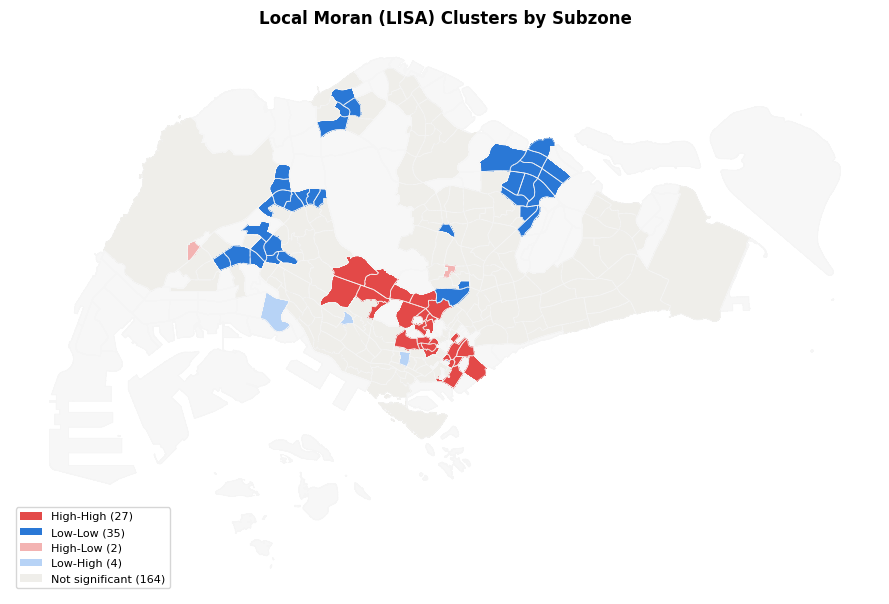

In [17]:
show_plot(lambda ax: draw_lisa_map(ax, sz["subzones"], sz_df, "Subzone"), OUT_SZ / "local_moran_lisa_map.png")

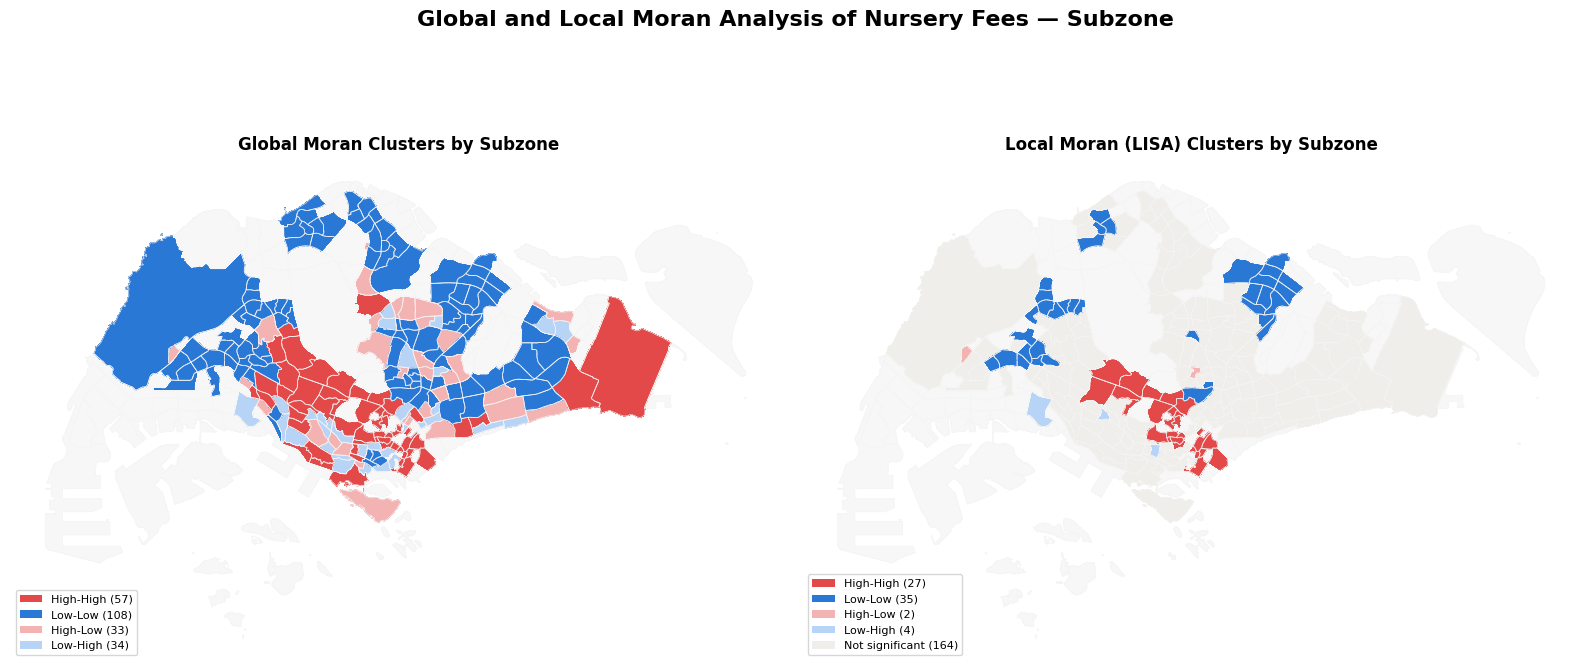

In [18]:
# Global quadrant map beside the significant LISA map (kept for the subzone level only, as in the script).
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))
draw_global_moran_cluster_map(axes[0], sz["subzones"], sz_df, "Subzone")
draw_lisa_map(axes[1], sz["subzones"], sz_df, "Subzone")
fig.suptitle("Global and Local Moran Analysis of Nursery Fees — Subzone", fontsize=16, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(OUT_SZ / "global_moran_clusters_lisa_side_by_side.png", dpi=220, bbox_inches="tight")
plt.show()

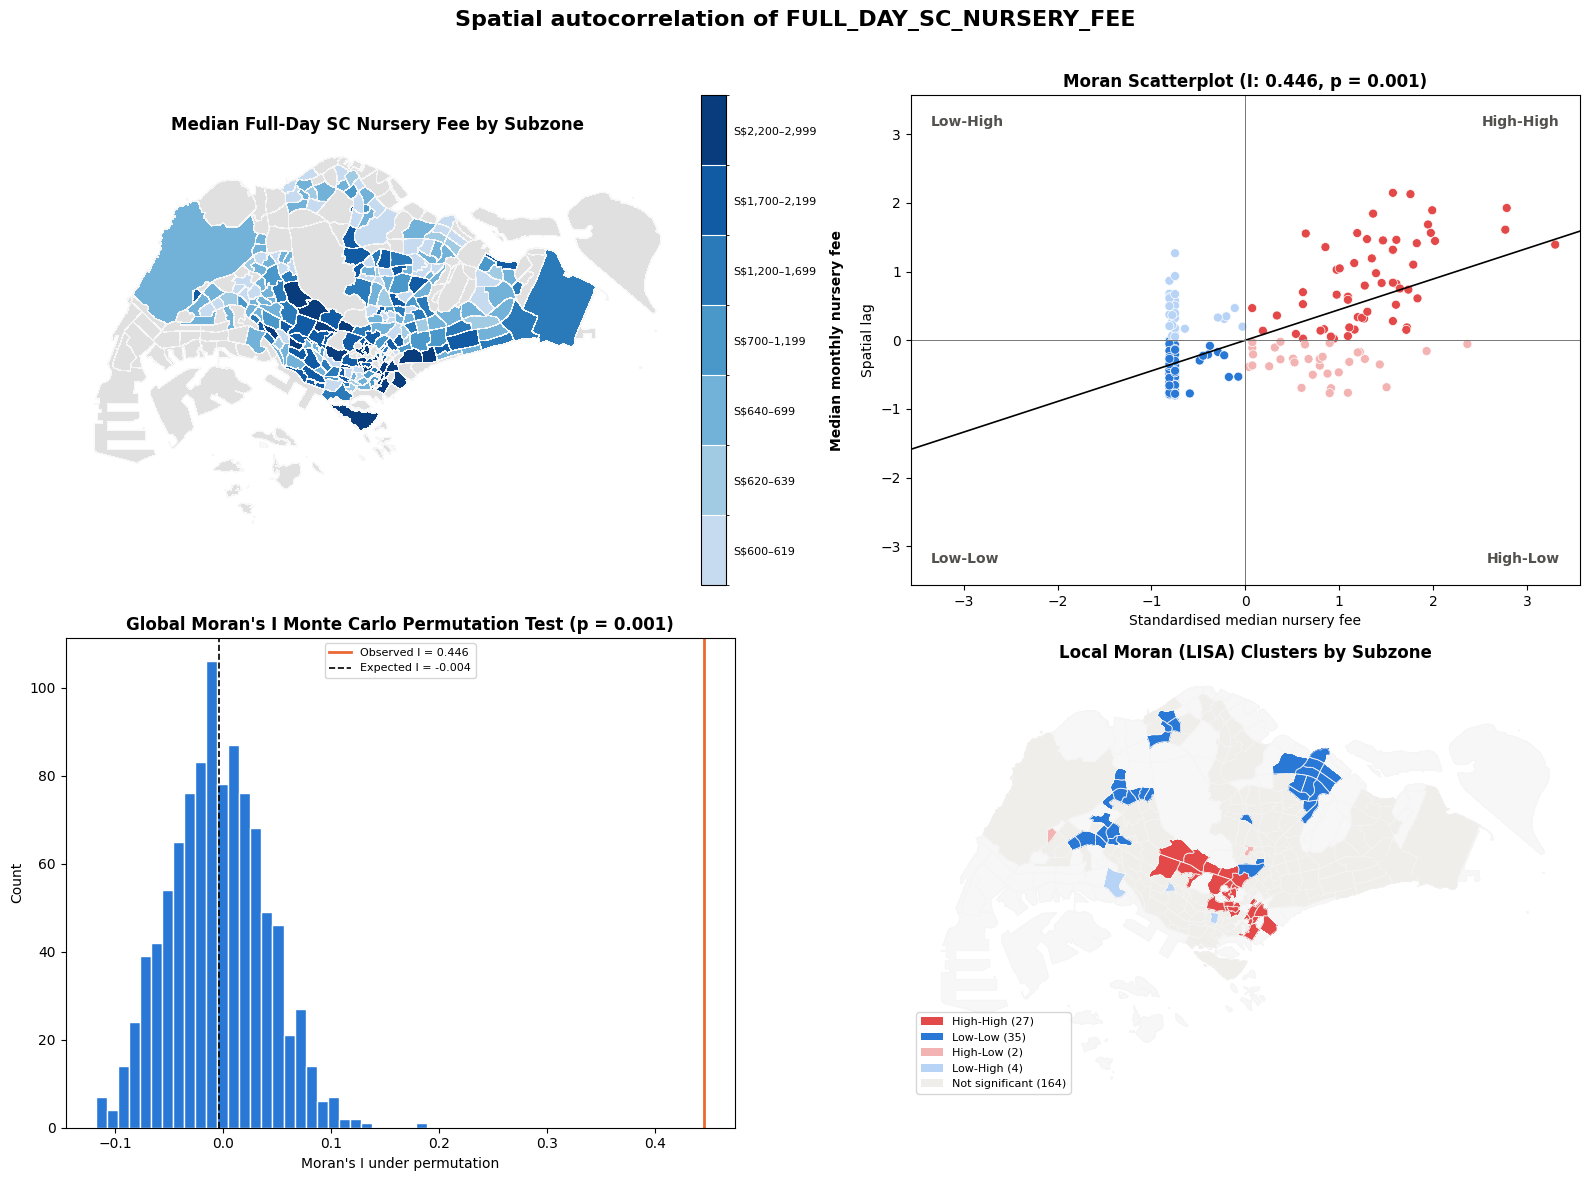

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
draw_fee_map(axes[0, 0], sz["subzones"], sz_df, "Subzone")
draw_moran_scatter(axes[0, 1], sz["z"], sz["lag"], sz["observed_i"], sz["global_p"],
                   sz_df["planning_area"].to_numpy(), annotate_names=False)
draw_permutation(axes[1, 0], sz["global_perm"], sz["observed_i"], sz["expected_i"], sz["global_p"])
draw_lisa_map(axes[1, 1], sz["subzones"], sz_df, "Subzone")
fig.suptitle("Spatial autocorrelation of FULL_DAY_SC_NURSERY_FEE", fontsize=16, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.97))
fig.savefig(OUT_SZ / "spatial_autocorrelation_overview.png", dpi=220, bbox_inches="tight")
plt.show()

In [20]:
significant_sz = write_summary(sz, OUT_SZ, "subzone", "subzones")
print(f"subzones locally significant at p < 0.05: {len(significant_sz)}; at FDR q < 0.05: "
      f"{int((sz_df['local_fdr_q'] < 0.05).sum())}")
print(significant_sz.head(20).round(4).to_string(index=False))

subzones locally significant at p < 0.05: 68; at FDR q < 0.05: 17
         subzone  median_fee_sgd  centre_count lisa_cluster_p05  local_moran_i  local_permutation_p  local_fdr_q
       BOULEVARD        2480.000             3        High-High         3.7625                0.001       0.0258
       CAIRNHILL        2200.000             1        High-High         3.3686                0.001       0.0258
   CLIFFORD PIER        2450.000             1        High-High         3.2752                0.001       0.0258
   GOODWOOD PARK        2129.500             2        High-High         2.1279                0.001       0.0258
     LEONIE HILL        3355.000             2        High-High         4.5898                0.001       0.0258
         MALCOLM        1580.000             1        High-High         0.9980                0.001       0.0258
   MARINA CENTRE        2325.000             4        High-High         3.7366                0.001       0.0258
    MARINA SOUTH        3010.0

## 5. Files written

In [21]:
for folder, table in ((OUT_PA, pa_df), (OUT_SZ, sz_df)):
    print(f"{folder.relative_to(ROOT)}/  ({len(table)} units, {PERMUTATIONS} permutations)")
    for f in sorted(folder.iterdir()):
        print(f"  {f.name}")
print(f"\nHeadline: planning-area Moran's I = {pa['observed_i']:.3f} (p = {pa['global_p']:.3f}); "
      f"subzone Moran's I = {sz['observed_i']:.3f} (p = {sz['global_p']:.3f})")

output/spatial_autocorrelation_nursery_fee_planning_area/  (42 units, 999 permutations)
  analysis_summary.md
  global_moran_cluster_map.png
  global_moran_clusters_lisa_side_by_side.png
  global_moran_permutation.png
  global_moran_permutations.csv
  global_moran_scatterplot.png
  local_moran_lisa_map.png
  nursery_fee_choropleth.png
  planning_area_nursery_fee_moran.csv
  spatial_autocorrelation_overview.png
output/spatial_autocorrelation_nursery_fee_subzone/  (232 units, 999 permutations)
  analysis_summary.md
  global_moran_cluster_map.png
  global_moran_clusters_lisa_side_by_side.png
  global_moran_permutation.png
  global_moran_permutations.csv
  global_moran_scatterplot.png
  local_moran_lisa_map.png
  nursery_fee_choropleth.png
  spatial_autocorrelation_overview.png
  subzone_nursery_fee_moran.csv

Headline: planning-area Moran's I = 0.511 (p = 0.001); subzone Moran's I = 0.446 (p = 0.001)
